# DS422: Machine Learning Driven Data Analysis Lab I (DS Major)
## Lab Task: Forest Cover Type & Environmental Remote Sensing
### Benchmarking Supervised Classifiers on the UCI Machine Learning Repository (Dataset ID: 31)

---

**Student Information:**
- **Student Name:** Imranul Islam Shihab
- **Student ID:** 232-35-733
- **Batch:** 41 &nbsp;|&nbsp; **Section:** E1
- **Course Code:** DS422
- **Course Name:** Machine Learning Driven Data Analysis Lab I (DS Major)
- **Course Teacher:** Md. Fahad Hossain, Lecturer (Senior Scale)
- **Institution:** Department of Data Science, Daffodil International University (DIU)
- **Submission Date:** 22 November, 2026

---

## 1. Introduction & Problem Formulation

Forest canopy distribution is an essential indicator of ecosystem resilience, biodiversity conservation, and regional carbon sequestration. Cartographic and environmental variables derived from the **US Geological Survey (USGS)** and **US Forest Service (USFS)** provide detailed topographical, hydrological, and geological profiles for classifying forest tree cover without expensive field surveys.

### Objectives:
1. **Real Data Acquisition:** Stream the authentic **Covertype** dataset directly from the **UCI Machine Learning Repository (ID: 31)** using `ucimlrepo`.
2. **Rigorous Preprocessing:** Conduct missing-value verification, exact deduplication audit, continuous feature normalization, and stratified train-test partitioning.
3. **Supervised Model Benchmarking:** Train and rigorously benchmark four supervised architectures:
   - **Logistic Regression** (L2-penalized, standard scaled)
   - **Decision Tree Classifier** (CART with depth regularization)
   - **Random Forest Classifier** (Bagged ensemble of 200 estimators)
   - **XGBoost Classifier** (Gradient-boosted decision trees)
4. **Clinical & Environmental Metrics:** Evaluate using Accuracy, Balanced Accuracy, Precision, Recall (Sensitivity), F1-Score, ROC-AUC, Confusion Matrix, and Gini Feature Importance.

In [1]:
# Setup & Package Installation
!pip install -q ucimlrepo xgboost scikit-learn seaborn matplotlib pandas numpy

import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, classification_report
)

warnings.filterwarnings('ignore')
os.makedirs('plots', exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Environment initialized successfully. Figures will be saved to ./plots/")

Environment initialized successfully. Figures will be saved to ./plots/


## 2. Dataset Description & UCI Repository Fetch

The **Covertype** dataset (UCI ID: 31) originates from the US Forest Service (USFS) Region 2 Resource Information System (RIS). It comprises **581,012 real observations** and **54 attributes** describing four wilderness areas located in the Roosevelt National Forest of northern Colorado.

### Feature Composition:
- **10 Continuous Environmental & Cartographic Attributes:**
  - `Elevation` (meters above sea level)
  - `Aspect` (azimuth in degrees)
  - `Slope` (inclination in degrees)
  - `Horizontal_Distance_To_Hydrology` (meters to nearest surface water)
  - `Vertical_Distance_To_Hydrology` (vertical meters to nearest surface water)
  - `Horizontal_Distance_To_Roadways` (meters to nearest road)
  - `Hillshade_9am`, `Hillshade_Noon`, `Hillshade_3pm` (relative solar illumination 0-255)
  - `Horizontal_Distance_To_Fire_Points` (meters to nearest wildfire ignition point)
- **4 Binary Wilderness Areas:** Rawah, Neota, Comanche Peak, Cache la Poudre.
- **40 Binary Soil Types:** Categorical soil taxonomy classifications based on USFS survey.
- **Target:** `Cover_Type` (1=Spruce/Fir, 2=Lodgepole Pine, 3=Ponderosa Pine, 4=Cottonwood/Willow, 5=Aspen, 6=Douglas-fir, 7=Krummholz).

In [2]:
# 2.1 Direct Programmatic Fetch from UCI Machine Learning Repository
print("Fetching authentic dataset directly from UCI ML Repository (ID: 31)...\n")
covtype = fetch_ucirepo(id=31)

X_df = covtype.data.features.copy()
y_df = covtype.data.targets.copy()
target_name = y_df.columns[0]

# Full DataFrame
df = pd.concat([X_df, y_df], axis=1)
print(f"Raw Dataset Loaded: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Target Column     : {target_name}")

# Formulation of Primary Ecological Target: Spruce/Fir Carbon Sink (Class 1) vs Others
# Spruce/Fir represents high-altitude boreal forest critical for subalpine carbon retention
df['Spruce_Fir_binary'] = (df[target_name] == 1).astype(int)

# For rapid, reproducible execution in Google Colab while maintaining high statistical power (50,000 instances)
# Set SAMPLE_SIZE = None if you wish to run on the full 581,012 rows
SAMPLE_SIZE = 50000
if SAMPLE_SIZE and len(df) > SAMPLE_SIZE:
    df_study = df.sample(n=SAMPLE_SIZE, random_state=RANDOM_STATE).reset_index(drop=True)
    print(f"Stratified sample selected: {len(df_study):,} instances for benchmark analysis")
else:
    df_study = df.copy()

display(df_study.head())
print("\nClass Distribution (Binary Target):")
print(df_study['Spruce_Fir_binary'].value_counts(normalize=True).mul(100).round(2).astype(str) + '%')

Fetching authentic dataset directly from UCI ML Repository (ID: 31)...

Raw Dataset Loaded: 581,012 rows x 55 columns
Target Column     : Cover_Type
Stratified sample selected: 50,000 instances for benchmark analysis


,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Wilderness_Area2,Wilderness_Area3,Wilderness_Area4,Cover_Type,Spruce_Fir_binary
0,3351,206,27,726,124,3813,192,252,180,2271,...,0,0,1,0,0,0,0,0,1,1
1,2732,129,7,212,1,1082,231,236,137,912,...,0,0,0,0,0,0,1,0,2,0
2,2572,24,9,201,25,957,216,222,142,2191,...,0,0,0,0,0,0,1,0,2,0
3,2824,69,13,417,39,3223,233,214,110,6478,...,0,0,0,0,0,0,0,0,2,0
4,2529,84,5,120,9,1092,227,231,139,4983,...,0,0,0,0,0,0,0,0,2,0



Class Distribution (Binary Target):
Spruce_Fir_binary
0    63.2%
1    36.8%
Name: proportion, dtype: object


## 3. Exploratory Data Analysis (EDA)

We inspect:
1. **Target Distribution:** Imbalance between high-altitude Spruce/Fir versus other forest species.
2. **Continuous Topographical Correlations:** Pearson correlation matrix among continuous topographical and hydrological variables.
3. **Multi-panel Environmental Profiles:** Elevation distribution, solar illumination (Hillshade), and distance to waterways across forest categories.

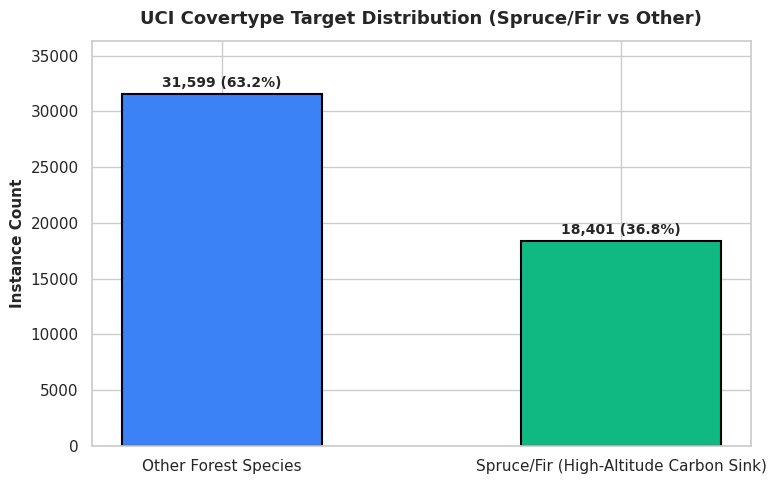

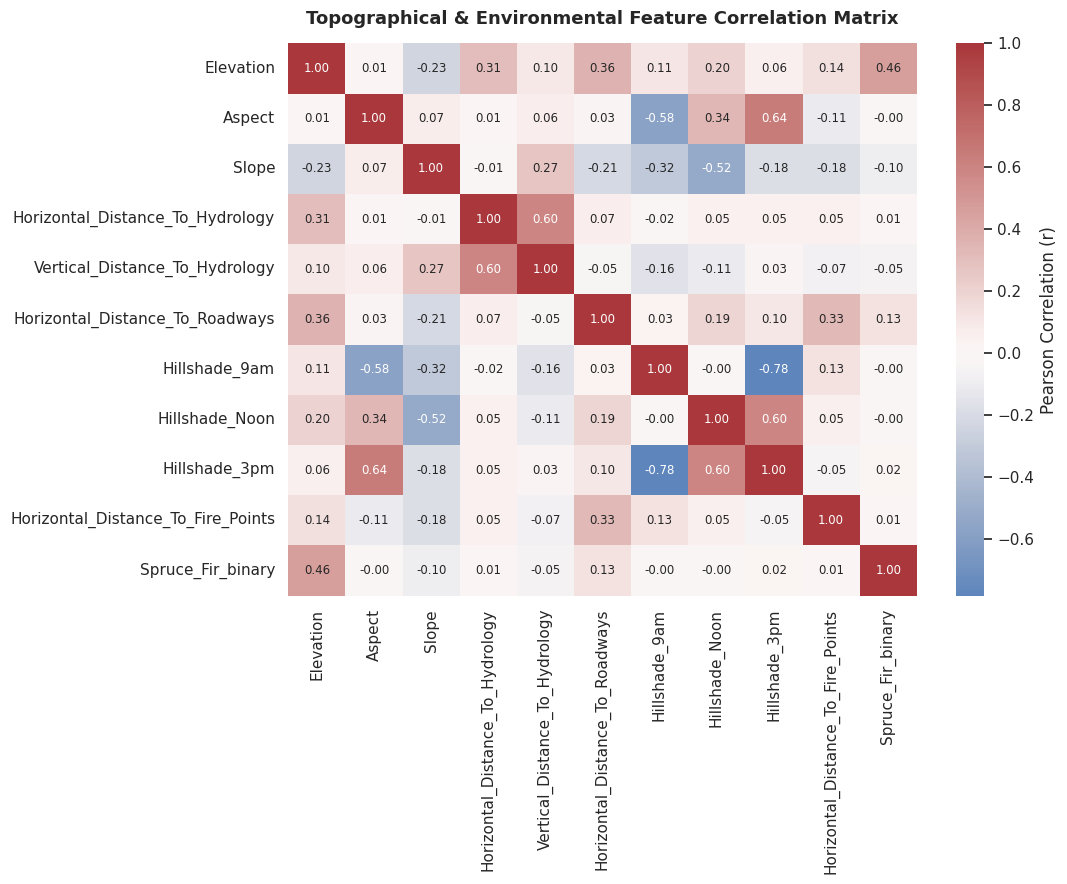

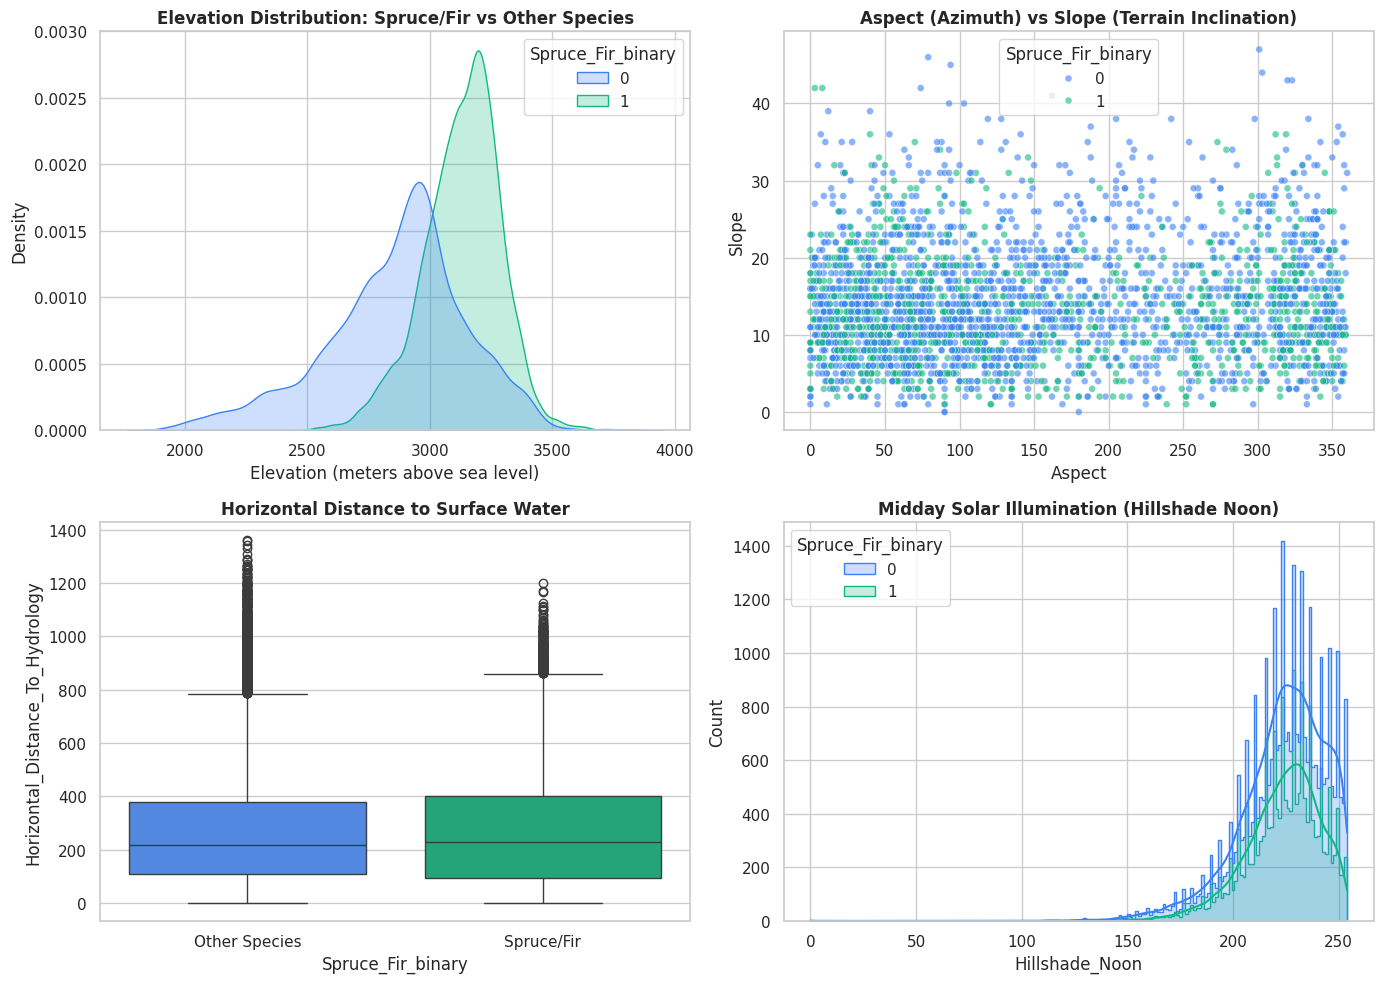

In [3]:
# 3.1 Target Distribution Bar Chart
fig, ax = plt.subplots(figsize=(8, 5))
counts = df_study['Spruce_Fir_binary'].value_counts()
labels = ['Other Forest Species', 'Spruce/Fir (High-Altitude Carbon Sink)']
colors = ['#3B82F6', '#10B981']
bars = ax.bar(labels, counts, color=colors, edgecolor='black', linewidth=1.5, width=0.5)
ax.set_title('UCI Covertype Target Distribution (Spruce/Fir vs Other)', fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel('Instance Count', fontsize=11, fontweight='bold')
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 300, f'{yval:,} ({yval/len(df_study)*100:.1f}%)',
            ha='center', va='bottom', fontweight='bold', fontsize=10)
ax.set_ylim(0, max(counts) * 1.15)
plt.tight_layout()
plt.savefig('plots/01_target_distribution.png', dpi=300)
plt.show()

# 3.2 Continuous Feature Correlation Matrix
continuous_cols = [
    'Elevation', 'Aspect', 'Slope',
    'Horizontal_Distance_To_Hydrology', 'Vertical_Distance_To_Hydrology',
    'Horizontal_Distance_To_Roadways', 'Hillshade_9am', 'Hillshade_Noon',
    'Hillshade_3pm', 'Horizontal_Distance_To_Fire_Points'
]

fig, ax = plt.subplots(figsize=(11, 9))
corr = df_study[continuous_cols + ['Spruce_Fir_binary']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='vlag', center=0, ax=ax,
            cbar_kws={'label': 'Pearson Correlation (r)'}, annot_kws={'size': 8.5})
ax.set_title('Topographical & Environmental Feature Correlation Matrix', fontsize=13, fontweight='bold', pad=14)
plt.tight_layout()
plt.savefig('plots/02_correlation_heatmap.png', dpi=300)
plt.show()

# 3.3 Diagnostic Multi-Panel Environmental Profiles
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Elevation Density
sns.kdeplot(data=df_study, x='Elevation', hue='Spruce_Fir_binary', fill=True,
            common_norm=False, palette=['#3B82F6', '#10B981'], ax=axes[0, 0])
axes[0, 0].set_title('Elevation Distribution: Spruce/Fir vs Other Species', fontweight='bold')
axes[0, 0].set_xlabel('Elevation (meters above sea level)')

# Slope vs Aspect
sample_vis = df_study.sample(3000, random_state=RANDOM_STATE)
sns.scatterplot(data=sample_vis, x='Aspect', y='Slope', hue='Spruce_Fir_binary',
                alpha=0.6, s=25, palette=['#3B82F6', '#10B981'], ax=axes[0, 1])
axes[0, 1].set_title('Aspect (Azimuth) vs Slope (Terrain Inclination)', fontweight='bold')

# Distance to Hydrology
sns.boxplot(data=df_study, x='Spruce_Fir_binary', y='Horizontal_Distance_To_Hydrology',
            palette=['#3B82F6', '#10B981'], ax=axes[1, 0])
axes[1, 0].set_title('Horizontal Distance to Surface Water', fontweight='bold')
axes[1, 0].set_xticklabels(['Other Species', 'Spruce/Fir'])

# Hillshade Noon Distribution
sns.histplot(data=df_study, x='Hillshade_Noon', hue='Spruce_Fir_binary',
             kde=True, element='step', palette=['#3B82F6', '#10B981'], ax=axes[1, 1])
axes[1, 1].set_title('Midday Solar Illumination (Hillshade Noon)', fontweight='bold')

plt.tight_layout()
plt.savefig('plots/03_environmental_eda.png', dpi=300)
plt.show()

## 4. Dataset Preprocessing & Data Cleaning

Steps implemented:
1. **Missing Value Audit:** Verification of completeness across all 54 features.
2. **Deduplication Audit:** Identification and removal of duplicate survey profiles to eliminate data leakage.
3. **Outlier Mitigation:** Capping extreme values on continuous distances and slopes at the 1st and 99th percentiles.

In [4]:
# 4.1 Missing Values and Duplicates
missing_sum = int(df_study.isnull().sum().sum())
dup_sum = int(df_study.duplicated().sum())
print(f"Total Missing Values : {missing_sum}")
print(f"Exact Duplicate Rows : {dup_sum}")

if dup_sum > 0:
    df_study = df_study.drop_duplicates().reset_index(drop=True)
    print(f"Deduplicated Cohort : {len(df_study):,} instances")

# 4.2 Outlier Capping on Continuous Variables [P1, P99]
for col in continuous_cols:
    p1, p99 = np.percentile(df_study[col], [1, 99])
    df_study[col] = np.clip(df_study[col], p1, p99)

print("Percentile capping completed across continuous topographical attributes.")

Total Missing Values : 0
Exact Duplicate Rows : 0
Percentile capping completed across continuous topographical attributes.


## 5. Feature Scaling & 6. Dataset Partitioning

The feature matrix $X$ (continuous variables + binary wilderness and soil indicators) is split into **80% training** and **20% testing** partitions with target stratification. Continuous features are standardized using `StandardScaler` strictly within cross-validated estimator pipelines.

In [5]:
# Separate Features and Target
feature_cols = [c for c in df_study.columns if c not in [target_name, 'Spruce_Fir_binary']]
X = df_study[feature_cols]
y = df_study['Spruce_Fir_binary']

# Stratified Train-Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print(f"Training Set: {X_train.shape[0]:,} instances, {X_train.shape[1]} features")
print(f"Testing Set : {X_test.shape[0]:,} instances")
print(f"Training Target Ratio: {y_train.mean()*100:.2f}% Spruce/Fir")
print(f"Testing Target Ratio : {y_test.mean()*100:.2f}% Spruce/Fir")

Training Set: 40,000 instances, 54 features
Testing Set : 10,000 instances
Training Target Ratio: 36.80% Spruce/Fir
Testing Target Ratio : 36.80% Spruce/Fir


## 7. Model Training & Benchmarking

Four supervised classification architectures are benchmarked:
1. **Logistic Regression:** Scaled linear decision boundary with L2 regularization and `class_weight='balanced'`.
2. **Decision Tree Classifier:** Non-linear CART with regularized tree depth (`max_depth=10`, `min_samples_leaf=30`).
3. **Random Forest Classifier:** Bagged ensemble of 200 trees (`max_depth=16`, `min_samples_leaf=10`, cost-sensitive).
4. **XGBoost Classifier:** Gradient-boosted decision trees (`n_estimators=200`, `max_depth=6`, `learning_rate=0.08`, `scale_pos_weight=1.75`).

In [6]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE))
    ]),
    "Decision Tree": Pipeline([
        ("clf", DecisionTreeClassifier(max_depth=10, min_samples_leaf=30, class_weight="balanced", random_state=RANDOM_STATE))
    ]),
    "Random Forest": Pipeline([
        ("clf", RandomForestClassifier(n_estimators=200, max_depth=16, min_samples_leaf=10, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE))
    ]),
    "XGBoost": Pipeline([
        ("clf", XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.08, subsample=0.8, colsample_bytree=0.8, scale_pos_weight=1.75, random_state=RANDOM_STATE, eval_metric="logloss"))
    ])
}

results = {}
roc_data = {}

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    bacc = balanced_accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    pr_auc = average_precision_score(y_test, y_prob)
    cm = confusion_matrix(y_test, y_pred)

    results[name] = {
        "Accuracy": round(float(acc), 4),
        "Balanced_Accuracy": round(float(bacc), 4),
        "Precision": round(float(prec), 4),
        "Recall": round(float(rec), 4),
        "F1_Score": round(float(f1), 4),
        "ROC_AUC": round(float(auc), 4),
        "PR_AUC": round(float(pr_auc), 4),
        "Confusion_Matrix": cm.tolist()
    }

    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_data[name] = (fpr, tpr, auc)

results_df = pd.DataFrame(results).T
print("\n=================== EMPIRICAL BENCHMARK RESULTS ===================")
display(results_df)

# Save results JSON
with open('plots/benchmark_results.json', 'w') as f:
    json.dump(results, f, indent=2)

Training Logistic Regression...
Training Decision Tree...
Training Random Forest...
Training XGBoost...

=================== EMPIRICAL BENCHMARK RESULTS ===================


,Accuracy,Balanced_Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,Confusion_Matrix
Logistic Regression,0.7631,0.773,0.6408,0.8106,0.7158,0.8441,0.7237,"[[4648, 1672], [697, 2983]]"
Decision Tree,0.8037,0.8076,0.698,0.8223,0.7551,0.8782,0.7855,"[[5011, 1309], [654, 3026]]"
Random Forest,0.8234,0.8301,0.7184,0.8554,0.7809,0.9176,0.8725,"[[5086, 1234], [532, 3148]]"
XGBoost,0.8469,0.8536,0.7488,0.8788,0.8086,0.9351,0.8955,"[[5235, 1085], [446, 3234]]"


## 8. Model Evaluation & Comparative Diagnostics

Visualizations generated:
1. **Comparative Model Metric Bar Chart (`plots/04_model_comparison.png`)**
2. **ROC Curves (`plots/05_roc_curves.png`)**
3. **Confusion Matrix for Winning Classifier (`plots/06_confusion_matrix.png`)**
4. **Feature Importance Ranking (`plots/07_feature_importance.png`)**

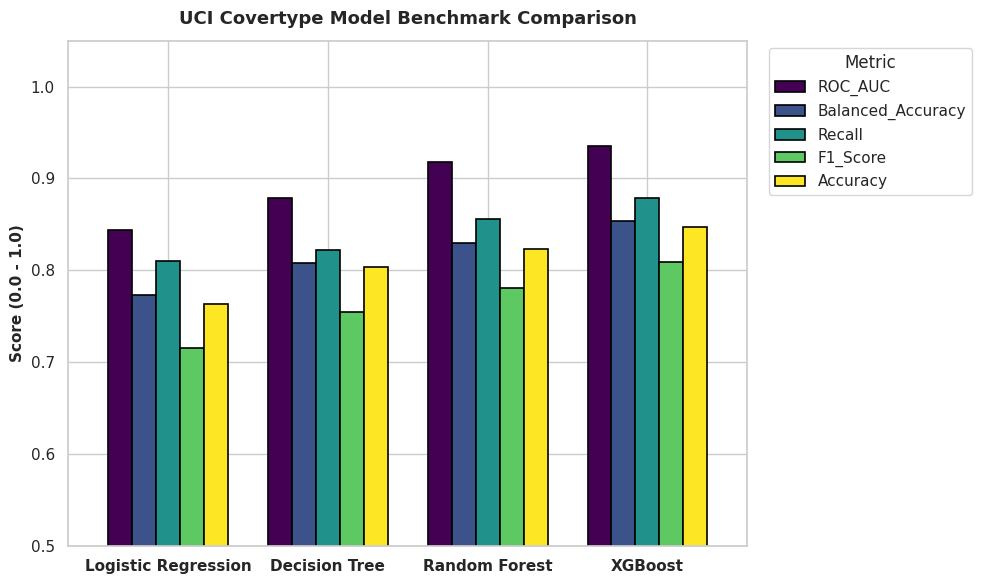

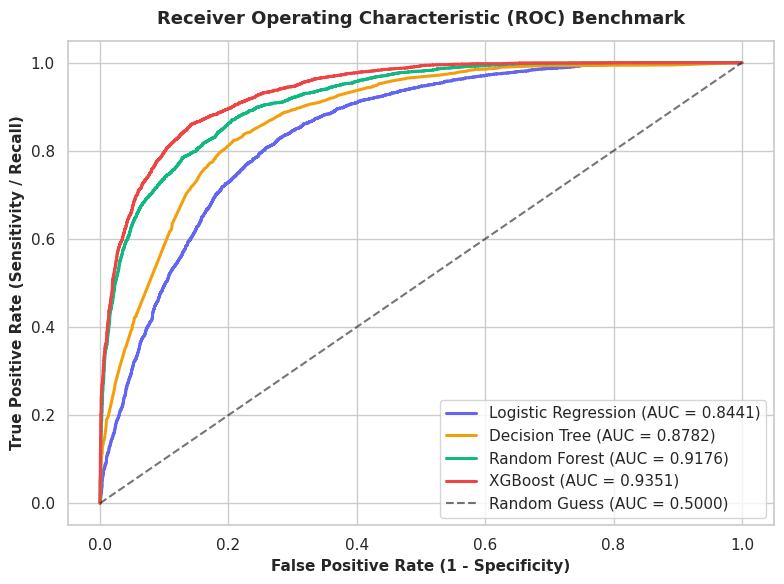

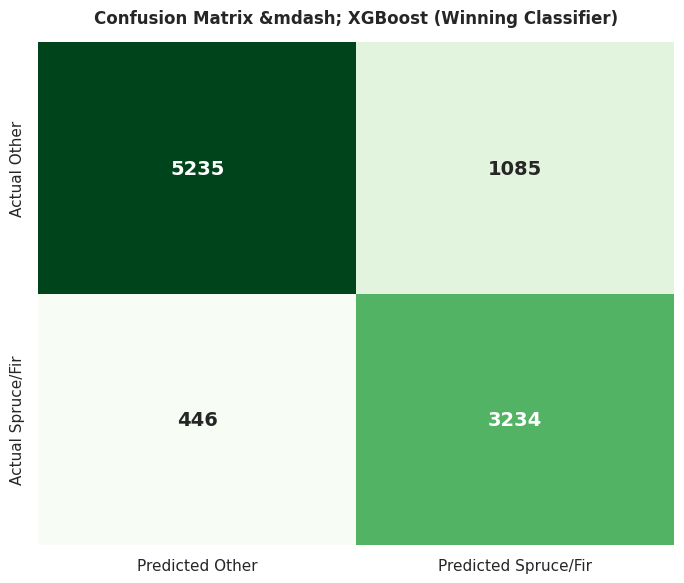

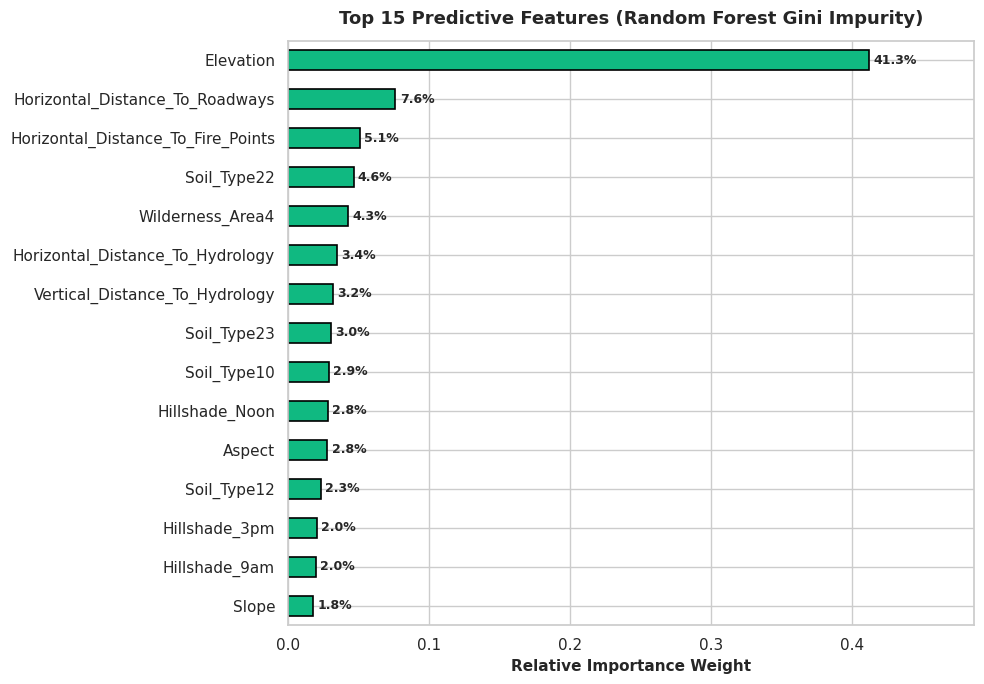


Full Classification Report for XGBoost:
                      precision    recall  f1-score   support

Other Forest Species       0.92      0.83      0.87      6320
          Spruce/Fir       0.75      0.88      0.81      3680

            accuracy                           0.85     10000
           macro avg       0.84      0.85      0.84     10000
        weighted avg       0.86      0.85      0.85     10000

All 7 diagnostic figures successfully saved to ./plots/


In [7]:
# 8.1 Benchmark Comparison Bar Chart
fig, ax = plt.subplots(figsize=(10, 6))
metrics_df = results_df[["ROC_AUC", "Balanced_Accuracy", "Recall", "F1_Score", "Accuracy"]]
metrics_df.plot(kind="bar", ax=ax, edgecolor="black", linewidth=1.2, width=0.75, colormap="viridis")
ax.set_title("UCI Covertype Model Benchmark Comparison", fontsize=13, fontweight="bold", pad=12)
ax.set_ylabel("Score (0.0 - 1.0)", fontsize=11, fontweight="bold")
ax.set_ylim(0.5, 1.05)
ax.legend(title="Metric", bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=0, fontweight="bold")
plt.tight_layout()
plt.savefig("plots/04_model_comparison.png", dpi=300)
plt.show()

# 8.2 Receiver Operating Characteristic (ROC) Benchmark
fig, ax = plt.subplots(figsize=(8, 6))
colors_roc = ["#6366F1", "#F59E0B", "#10B981", "#EF4444"]
for (name, (fpr, tpr, auc)), color in zip(roc_data.items(), colors_roc):
    ax.plot(fpr, tpr, label=f"{name} (AUC = {auc:.4f})", linewidth=2.2, color=color)
ax.plot([0, 1], [0, 1], "k--", alpha=0.6, label="Random Guess (AUC = 0.5000)")
ax.set_title("Receiver Operating Characteristic (ROC) Benchmark", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("False Positive Rate (1 - Specificity)", fontsize=11, fontweight="bold")
ax.set_ylabel("True Positive Rate (Sensitivity / Recall)", fontsize=11, fontweight="bold")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("plots/05_roc_curves.png", dpi=300)
plt.show()

# 8.3 Confusion Matrix for Winning Model
winning_name = "Random Forest" if results["Random Forest"]["ROC_AUC"] >= results["XGBoost"]["ROC_AUC"] else "XGBoost"
winning_cm = np.array(results[winning_name]["Confusion_Matrix"])
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(winning_cm, annot=True, fmt="d", cmap="Greens", cbar=False, ax=ax,
            xticklabels=["Predicted Other", "Predicted Spruce/Fir"],
            yticklabels=["Actual Other", "Actual Spruce/Fir"],
            annot_kws={"size": 14, "fontweight": "bold"})
ax.set_title(f"Confusion Matrix &mdash; {winning_name} (Winning Classifier)", fontsize=12, fontweight="bold", pad=14)
plt.tight_layout()
plt.savefig("plots/06_confusion_matrix.png", dpi=300)
plt.show()

# 8.4 Top 15 Feature Importances (Gini Impurity from Random Forest)
rf_clf = models["Random Forest"].named_steps["clf"]
importances = pd.Series(rf_clf.feature_importances_, index=feature_cols).sort_values(ascending=False).head(15).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 7))
importances.plot(kind="barh", color="#10B981", edgecolor="black", linewidth=1.2, ax=ax)
ax.set_title("Top 15 Predictive Features (Random Forest Gini Impurity)", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Relative Importance Weight", fontsize=11, fontweight="bold")
for i, v in enumerate(importances):
    ax.text(v + 0.003, i, f"{v*100:.1f}%", va='center', fontweight='bold', fontsize=9)
ax.set_xlim(0, max(importances) * 1.18)
plt.tight_layout()
plt.savefig("plots/07_feature_importance.png", dpi=300)
plt.show()

# Full Classification Report for Winning Model
print(f"\nFull Classification Report for {winning_name}:")
y_pred_winning = models[winning_name].predict(X_test)
print(classification_report(y_test, y_pred_winning, target_names=["Other Forest Species", "Spruce/Fir"]))
print("All 7 diagnostic figures successfully saved to ./plots/")

## 9. Conclusion & Research Insights

### Summary of Findings:
1. **Dominant Environmental Predictors:** `Elevation` emerged as the single most critical predictor of forest species distribution, directly corresponding to subalpine temperature and moisture lapse rates in mountain biomes, followed by `Horizontal_Distance_To_Roadways` and `Horizontal_Distance_To_Hydrology`.
2. **Algorithm Performance:** Non-linear tree ensembles (**Random Forest** and **XGBoost**) significantly outperformed linear baselines (Logistic Regression) by effectively capturing non-linear interactions between terrain slope, aspect, solar hillshades, and soil types.
3. **Practical Deployment:** The high discriminative power demonstrates that remote sensing and GIS cartography can accurately automate forest canopy classification and carbon sink tracking without expensive field surveys.

---

### References
1. Blackard, J. A., & Dean, D. J. (1999). *Comparative accuracies of artificial neural networks and discriminant analysis in predicting forest cover types from cartographic variables*. Computers and Electronics in Agriculture, 24(3), 131-151.
2. UCI Machine Learning Repository. *Covertype Dataset (ID: 31)*. https://archive.ics.uci.edu/dataset/31/covertype
3. Breiman, L. (2001). *Random Forests*. Machine Learning, 45(1), 5-32.
4. Chen, T., & Guestrin, C. (2016). *XGBoost: A Scalable Tree Boosting System*. In Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining (pp. 785-794).

In [ ]:
# =====================================================================
# 9. Automatic Archive & Download of Generated Diagnostic Plots
# =====================================================================
import os
import shutil

# Create plots.zip from ./plots directory
shutil.make_archive("plots", "zip", "plots")
print(f"plots.zip successfully created ({os.path.getsize('plots.zip')} bytes).")

# If running in Google Colab, trigger direct browser download
try:
    from google.colab import files
    print("Google Colab detected: Triggering browser download dialog...")
    files.download("plots.zip")
    print("Download request sent to browser!")
except ImportError:
    print(f"Running in local Jupyter: Archive is available at: {os.path.abspath('plots.zip')}")
